# 02. Data Understanding: Eksplorasi Dataset Piksel Sentinel-2A
## Karakteristik Data Spektral dan Profil Tutupan Lahan Jawa Timur

# 2. Data Understanding & Karakteristik Data Spasial

## 2.1. Definisi Domain dan 6 Kelas Tutupan Lahan
Area of Interest (AOI) mencakup seluruh wilayah daratan dan perairan pesisir Provinsi Jawa Timur. Objek permukaan bumi dikelompokkan ke dalam 6 kelas tutupan lahan utama:

| No | Nama Kelas | Kode Label | Definisi & Karakteristik Objek | Respon Spektral Utama |
|---|---|---|---|---|
| 1 | Sawah | 1 | Lahan pertanian padi basah berpetak. Kondisi bervariasi dari genangan air awal tanam, fase vegetatif hijau pekat, hingga fase pematangan/panen. | Pantulan NIR sedang-tinggi pada fase vegetatif; nilai SWIR meningkat pada lahan bera/kering. |
| 2 | Bangunan | 2 | Kawasan terbangun perkotaan, permukiman, jalan aspal/beton, dan atap bangunan (genteng/seng). | Pantulan tinggi pada band SWIR (B11) dan Red (B04); nilai NDBI positif tinggi; NDVI rendah. |
| 3 | Hutan (Lahan Hijau)| 3 | Vegetasi alami kanopi pohon lebat, hutan pegunungan, perbukitan hijau, dan perkebunan tahunan rapat. | Pantulan sangat tinggi pada NIR (B08) akibat struktur sel daun; serapan kuat pada Red (B04); NDVI sangat tinggi. |
| 4 | Danau | 4 | Badan air tawar pedalaman (danau alami, waduk, telaga, bendungan) berarus tenang. | Penyerapan kuat pada inframerah (NIR dan SWIR); nilai NDWI dan MNDWI sangat positif; NDVI negatif. |
| 5 | Laut (Perairan Terbuka) | 5 | Badan air asin laut terbuka di pesisir utara dan selatan Jawa Timur serta Selat Madura. | Pantulan dominan pada band Blue (B02) dan Green (B03); penyerapan hampir total pada NIR/SWIR; NDWI tinggi. |
| 6 | Mangrove | 6 | Komunitas hutan bakau pesisir yang toleran terhadap air asin/payau, tumbuh di muara sungai dan pantai berlumpur. | Kombinasi sinyal vegetasi lebat (NIR tinggi) dan pengaruh substrat air/lumpur basah (SWIR rendah, MNDWI relatif tinggi dibanding hutan daratan). |

## 2.2. Karakteristik Citra Satelit Sentinel-2A Level-2A
Dataset citra satelit diperoleh dari satelit optik Sentinel-2A Level-2A (Bottom-of-Atmosphere / BOA Surface Reflectance) yang disediakan oleh European Space Agency (ESA) melalui Copernicus Data Space Ecosystem (CDSE). Akuisisi data dilakukan untuk rentang waktu **1 September 2026 – 30 September 2026** dengan ambang batas tutupan awan (cloud cover) maksimal 30%.

Band spektral yang digunakan meliputi:
*   **B02 (Blue - 490 nm):** Resolusi spasial 10 meter. Sensitif terhadap kedalaman air dan hamburan atmosfer.
*   **B03 (Green - 560 nm):** Resolusi spasial 10 meter. Puncak pantulan klorofil daun pada spektrum tampak dan deteksi air bersih.
*   **B04 (Red - 665 nm):** Resolusi spasial 10 meter. Pita serapan utama klorofil; sangat berguna membedakan vegetasi hidup dari tanah terbuka atau bangunan.
*   **B08 (Near Infrared / NIR - 842 nm):** Resolusi spasial 10 meter. Pantulan maksimal struktur kanopi sel mesofil daun vegetasi; diserap hampir sempurna oleh badan air jernih.
*   **B11 (Short-Wave Infrared / SWIR - 1610 nm):** Resolusi spasial 20 meter (di-resample ke 10 m). Sensitif terhadap kadar kelembapan tanah, kebasahan vegetasi, dan material semen/bebatuan bangunan.
*   **SCL (Scene Classification Layer):** Lapisan klasifikasi kualitas piksel otomatis untuk memfilter piksel yang mengandung awan (tebal, sedang, cirrus), bayangan awan (*cloud shadow*), serta piksel jenuh (defective).

## 2.3. Rekayasa Fitur Indeks Spektral (Spectral Indices)
Untuk mempertegas batas pemisah antar-kelas (*feature separability*), dihitung empat indeks spektral turunan yang dinormalisasi:

1.  **Normalized Difference Vegetation Index (NDVI)**
    Membedakan kerapatan dan kehijauan vegetasi dari non-vegetasi:
    $$NDVI = \frac{B08 - B04}{B08 + B04 + \epsilon}$$
2.  **Normalized Difference Water Index (NDWI - McFeeters)**
    Mengisolasi badan air permukaan terbuka dari tutupan lahan daratan:
    $$NDWI = \frac{B03 - B08}{B03 + B08 + \epsilon}$$
3.  **Modified Normalized Difference Water Index (MNDWI - Xu)**
    Meningkatkan akurasi deteksi air dengan menekan sinyal pantulan area terbangun/bangunan:
    $$MNDWI = \frac{B03 - B11}{B03 + B11 + \epsilon}$$
4.  **Normalized Difference Built-up Index (NDBI)**
    Mendeteksi konsentrasi kawasan terbangun, perkerasan beton, dan lahan terbuka:
    $$NDBI = \frac{B11 - B08}{B11 + B08 + \epsilon}$$

*(Nilai $\epsilon = 1 \times 10^{-9}$ ditambahkan pada penyebut untuk mencegah kesalahan pembagian dengan nol / division by zero).*

Notebook ini memuat dataset piksel Sentinel-2A hasil ekstraksi openEO (`piksel_s2.csv`), menganalisis struktur data, missing values, distribusi kelas, profil pantulan spektral (*spectral signature*), dan korelasi antar fitur spektral.

In [ ]:

import threading
import time
from datetime import datetime
from pathlib import Path

import geopandas as gpd
import numpy as np
import openeo
import pandas as pd
import rasterio
from openeo.extra.job_management import CsvJobDatabase, MultiBackendJobManager
from rasterio.features import rasterize
from rasterio.mask import mask as rio_mask
from rasterio.warp import transform as warp_transform
from rasterio.windows import Window
from shapely.geometry import box
from shapely.validation import make_valid

# ==============================================================================
# KONFIGURASI
# ==============================================================================
SUMBER = {  # nama kelas: (file, kode label)
   "Sawah": ("mystorage/jawatimur/sawah.zip", 1),
    "Bangunan": ("mystorage/jawatimur/pemukiman.zip", 2),
    "Hutan": ("mystorage/jawatimur/hutan.zip", 3),
    "Danau": ("mystorage/jawatimur/danau.zip", 4),
    "Laut": ("mystorage/jawatimur/laut.zip", 5),
    "Mangrove": ("mystorage/jawatimur/magrove.zip", 6),
}

TILE_DEG = 0.20      # ukuran tile ~22 km (~2200 x 2200 piksel @10 m)
BUFFER_DEG = 0.005   # margin ~500 m di sekeliling sampel

TANGGAL = ["2026-09-01", "2026-09-30"]
BANDS = ["B02", "B03", "B04", "B08", "B11"]  # Blue, Green, Red, NIR, SWIR
PAKAI_MASK_SCL = True  # mask awan/bayangan per piksel pakai band SCL
MAX_CLOUD = 30         # filter awan level scene (kalau PAKAI_MASK_SCL=False, pakai ~10)

PARALEL = 2            # job bersamaan (akun gratis CDSE biasanya max 2)

# Ekstraksi piksel
MAKS_PIKSEL_PER_POLIGON = 2000  # None = ambil SEMUA piksel (hati-hati: poligon laut/hutan bisa jutaan -> CSV sangat besar)
SEED = 42
BUAT_RASTER_LABEL = True        # buat label_<tile>.tif di samping citra tiap tile

OUT_DIR = Path("hasil_s2_piksel")
JOB_DB_PATH = OUT_DIR / "daftar_job.csv"
PETA_CSV = OUT_DIR / "peta_sampel_tile.csv"
PIKSEL_OUT = OUT_DIR / "piksel_s2.csv"


# ==============================================================================
# 1. BACA & GABUNGKAN SAMPEL
# ==============================================================================
def baca_semua() -> gpd.GeoDataFrame:
    bagian = []
    for nama, (file, label) in SUMBER.items():
        g = gpd.read_file(file).to_crs("EPSG:4326")
        # nomor fitur asli di file sumber (dicatat SEBELUM filter agar tetap stabil)
        g["poligon_no"] = np.arange(len(g))
        g = g[g.geometry.notna() & ~g.geometry.is_empty].copy()
        g["geometry"] = g.geometry.apply(lambda x: x if x.is_valid else make_valid(x))
        g["label_teks"] = nama
        g["label"] = label
        g["poligon_id"] = [f"{nama}_{n:04d}" for n in g["poligon_no"]]
        g = g[["poligon_id", "poligon_no", "label", "label_teks", "geometry"]]
        print(f"Jumlah sampel {nama:<9}: {len(g)}  bounds={[round(v, 3) for v in g.total_bounds]}")
        bagian.append(g)

    gdf = gpd.GeoDataFrame(pd.concat(bagian, ignore_index=True), crs="EPSG:4326")
    print(f"Total sampel gabungan   : {len(gdf)}")
    return gdf


# ==============================================================================
# 2. BAGI JADI TILE (poligon masuk ke semua sel yang dilewatinya)
# ==============================================================================
def buat_tile(gdf: gpd.GeoDataFrame):
    T, B = TILE_DEG, BUFFER_DEG
    peta, batas, sel_xy = [], {}, {}

    for idx, geom in gdf.geometry.items():
        minx, miny, maxx, maxy = geom.bounds
        for gx in range(int(np.floor(minx / T)), int(np.floor(maxx / T)) + 1):
            for gy in range(int(np.floor(miny / T)), int(np.floor(maxy / T)) + 1):
                sel = box(gx * T, gy * T, (gx + 1) * T, (gy + 1) * T)
                if not geom.intersects(sel):
                    continue
                bagian = geom.intersection(sel)
                if bagian.is_empty:
                    continue
                b = bagian.bounds
                tid = f"x{gx}_y{gy}"
                peta.append({"tile_id": tid, "sampel_id": idx, "poligon_id": gdf.at[idx, "poligon_id"]})
                sel_xy[tid] = (gx, gy)
                if tid in batas:
                    o = batas[tid]
                    batas[tid] = (min(o[0], b[0]), min(o[1], b[1]), max(o[2], b[2]), max(o[3], b[3]))
                else:
                    batas[tid] = b

    tiles = pd.DataFrame(
        [
            {
                "tile_id": tid,
                "gx": sel_xy[tid][0],
                "gy": sel_xy[tid][1],
                "west": b[0] - B,
                "south": b[1] - B,
                "east": b[2] + B,
                "north": b[3] + B,
            }
            for tid, b in batas.items()
        ]
    )
    peta = pd.DataFrame(peta)
    tiles["n_sampel"] = tiles["tile_id"].map(peta.groupby("tile_id")["sampel_id"].nunique())

    lebar_km = (tiles.east - tiles.west) * 111.32 * np.cos(np.radians((tiles.north + tiles.south) / 2))
    tinggi_km = (tiles.north - tiles.south) * 110.57
    print(f"\nJumlah tile (job)       : {len(tiles)}")
    print(f"Ukuran tile terbesar    : {lebar_km.max():.1f} km x {tinggi_km.max():.1f} km")
    print(f"Total area diunduh      : {(lebar_km * tinggi_km).sum():,.0f} km2")
    return tiles, peta


# ==============================================================================
# 3. JALANKAN BATCH JOB PER TILE
# ==============================================================================
def _jam() -> str:
    return datetime.now().strftime("%H:%M:%S")


def start_job(row, connection, **kwargs):
    print(f"[{_jam()}] >> Mengirim job tile {row['tile_id']} ({row.get('n_sampel', '?')} poligon)...", flush=True)
    bbox = {
        "west": float(row["west"]),
        "south": float(row["south"]),
        "east": float(row["east"]),
        "north": float(row["north"]),
    }
    bands = BANDS + ["SCL"] if PAKAI_MASK_SCL else BANDS
    cube = connection.load_collection(
        "SENTINEL2_L2A",
        spatial_extent=bbox,
        temporal_extent=TANGGAL,
        bands=bands,
        max_cloud_cover=MAX_CLOUD,
    )

    if PAKAI_MASK_SCL:
        scl = cube.band("SCL")
        # 1=jenuh, 3=bayangan awan, 8/9=awan sedang/tinggi, 10=cirrus
        mask_awan = (scl == 1) | (scl == 3) | (scl == 8) | (scl == 9) | (scl == 10)
        cube = cube.filter_bands(BANDS).mask(mask_awan)

    komposit = cube.median_time()
    return komposit.create_job(title=f"s2_{row['tile_id']}", out_format="GTiff")


INTERVAL_LAPOR = 30  # detik antar laporan progres di terminal


class ManagerBerlapor(MultiBackendJobManager):
    """Manager job yang mencetak pesan saat job selesai / gagal."""

    def on_job_done(self, job, row):
        print(f"[{_jam()}] [OK]    Tile {row['tile_id']} selesai (job {job.job_id}), mengunduh hasil...", flush=True)
        super().on_job_done(job, row)
        print(f"[{_jam()}] [OK]    Tile {row['tile_id']} terunduh.", flush=True)

    def on_job_error(self, job, row):
        print(f"[{_jam()}] [ERROR] Tile {row['tile_id']} gagal (job {job.job_id}). Log disimpan di folder job.", flush=True)
        super().on_job_error(job, row)


def _lapor_berkala(job_db, berhenti: threading.Event):
    mulai = time.time()
    while not berhenti.wait(INTERVAL_LAPOR):
        try:
            df = job_db.read()
        except Exception:  # file sedang ditulis manager; lewati satu siklus
            continue
        n = len(df)
        hitung = df["status"].value_counts().to_dict()
        selesai = hitung.get("finished", 0)
        gagal = sum(hitung.get(s, 0) for s in ("error", "start_failed", "skipped"))
        jalan = hitung.get("running", 0) + hitung.get("queued", 0) + hitung.get("created", 0)
        belum = hitung.get("not_started", 0)
        persen = 100 * selesai / n if n else 0
        menit = (time.time() - mulai) / 60
        print(
            f"[{_jam()}] Progres job: {selesai}/{n} selesai ({persen:.0f}%) | "
            f"berjalan/antre {jalan} | belum mulai {belum} | gagal {gagal} | {menit:.1f} menit",
            flush=True,
        )


def jalankan_job(tiles: pd.DataFrame, ulangi_error: bool = True):
    OUT_DIR.mkdir(exist_ok=True)

    conn = openeo.connect("openeo.dataspace.copernicus.eu")
    conn.authenticate_oidc()

    manager = ManagerBerlapor(root_dir=OUT_DIR, poll_sleep=30)
    manager.add_backend("cdse", connection=conn, parallel_jobs=PARALEL)

    job_db = CsvJobDatabase(JOB_DB_PATH)
    if not job_db.exists():
        job_db.initialize_from_df(tiles)
    elif ulangi_error:
        df = job_db.read()
        gagal = df["status"].isin(["error", "start_failed", "skipped"])
        if gagal.any():
            print(f"Mengulang {int(gagal.sum())} job yang sebelumnya gagal.")
            df.loc[gagal, "status"] = "not_started"
            job_db.persist(df)

    # thread pemantau: cetak ringkasan status job tiap INTERVAL_LAPOR detik
    berhenti = threading.Event()
    pemantau = threading.Thread(target=_lapor_berkala, args=(job_db, berhenti), daemon=True)
    pemantau.start()
    try:
        manager.run_jobs(start_job=start_job, job_db=job_db)
    finally:
        berhenti.set()
        pemantau.join(timeout=5)

    df = job_db.read()
    print("\nRingkasan status job:")
    print(df["status"].value_counts().to_string())
    return df


# ==============================================================================
# 4. EKSTRAK KELAS PER PIKSEL -> CSV
# ==============================================================================
def _nama_band(src) -> list:
    desc = list(src.descriptions or [])
    if len(desc) == src.count and all(desc) and set(BANDS) <= set(desc):
        return desc
    return BANDS  # asumsi urutan band sama dengan permintaan


def _valid_mask(data, nodata, masked=None):
    """data: (band, H, W). Piksel valid = semua band terbatas, > 0, bukan nodata."""
    ok = np.isfinite(data).all(axis=0) & (data > 0).all(axis=0)
    if nodata is not None and not np.isnan(nodata):
        ok &= ~(data == nodata).any(axis=0)
    if masked is not None:
        ok &= ~masked
    return ok


def _piksel_geom(src, geom):
    """Semua piksel valid yang pusatnya di dalam geometri.
    Return (nilai[band, n], baris_raster, kolom_raster, x, y) dalam CRS raster, atau None."""
    nodata = src.nodata

    if geom.geom_type == "Point":
        rr, cc = src.index(geom.x, geom.y)
        if not (0 <= rr < src.height and 0 <= cc < src.width):
            return None
        data = src.read(window=Window(cc, rr, 1, 1)).astype("float64")  # (band,1,1)
        ok = _valid_mask(data, nodata)
        row0, col0 = rr, cc
    else:
        ok = None
        for all_touched in (False, True):  # poligon sangat kecil: coba lagi dengan all_touched
            try:
                arr, tr = rio_mask(src, [geom], crop=True, all_touched=all_touched, filled=False)
            except ValueError:  # tidak beririsan dengan raster
                return None
            data = np.ma.getdata(arr).astype("float64")
            ok = _valid_mask(data, nodata, np.ma.getmaskarray(arr).any(axis=0))
            row0 = int(round((tr.f - src.transform.f) / src.transform.e))
            col0 = int(round((tr.c - src.transform.c) / src.transform.a))
            if ok.any():
                break
        if ok is None or not ok.any():
            return None

    r_idx, c_idx = np.nonzero(ok)
    if len(r_idx) == 0:
        return None
    nilai = data[:, r_idx, c_idx]
    px_row, px_col = row0 + r_idx, col0 + c_idx
    xs, ys = rasterio.transform.xy(src.transform, px_row, px_col)
    return nilai, px_row, px_col, np.asarray(xs), np.asarray(ys)


def tambah_indeks(df: pd.DataFrame) -> pd.DataFrame:
    e = 1e-9
    df["NDVI"] = (df["B08"] - df["B04"]) / (df["B08"] + df["B04"] + e)
    df["NDWI"] = (df["B03"] - df["B08"]) / (df["B03"] + df["B08"] + e)
    df["MNDWI"] = (df["B03"] - df["B11"]) / (df["B03"] + df["B11"] + e)
    df["NDBI"] = (df["B11"] - df["B08"]) / (df["B11"] + df["B08"] + e)
    return df


def _tif_tile(r):
    tifs = sorted(p for p in OUT_DIR.glob(f"job_{r['id']}/*.tif") if not p.name.startswith("label_"))
    return tifs[0] if tifs else None


def ekstrak_piksel(gdf, db, peta) -> pd.DataFrame:
    rng = np.random.default_rng(SEED)
    T = TILE_DEG
    potongan = []
    selesai = db[db["status"] == "finished"]
    print(f"\nEkstraksi piksel dari {len(selesai)} tile yang selesai...")

    total_tile = len(selesai)
    total_piksel = 0
    t0 = time.time()

    for no_tile, (_, r) in enumerate(selesai.iterrows(), start=1):
        tif = _tif_tile(r)
        if tif is None:
            print(f"  [!] File .tif tidak ditemukan untuk tile {r['tile_id']} (job {r['id']})")
            continue

        cx0, cy0 = int(r["gx"]) * T, int(r["gy"]) * T
        ids = peta.loc[peta["tile_id"] == r["tile_id"], "sampel_id"].unique()
        n_poli = len(ids)
        piksel_tile = 0
        print(f"[{_jam()}] Tile {no_tile}/{total_tile} ({r['tile_id']}): {n_poli} poligon", flush=True)

        with rasterio.open(tif) as src:
            nama_band = _nama_band(src)
            sub_r = gdf.loc[ids].to_crs(src.crs)

            for no_poli, (idx, row) in enumerate(sub_r.iterrows(), start=1):
                if no_poli % 25 == 0 or no_poli == n_poli:
                    print(
                        f"    poligon {no_poli}/{n_poli} | piksel tile ini: {piksel_tile:,} | "
                        f"total: {total_piksel:,} | {(time.time() - t0) / 60:.1f} menit",
                        end="\r", flush=True,
                    )
                hasil = _piksel_geom(src, row.geometry)
                if hasil is None:
                    continue
                nilai, px_row, px_col, xs, ys = hasil

                lon, lat = warp_transform(src.crs, "EPSG:4326", xs.tolist(), ys.tolist())
                lon, lat = np.asarray(lon), np.asarray(lat)

                # hanya piksel yang pusatnya di dalam sel grid tile ini -> tidak ada duplikat antar-tile
                pilih = np.flatnonzero((lon >= cx0) & (lon < cx0 + T) & (lat >= cy0) & (lat < cy0 + T))
                if len(pilih) == 0:
                    continue
                if MAKS_PIKSEL_PER_POLIGON and len(pilih) > MAKS_PIKSEL_PER_POLIGON:
                    pilih = rng.choice(pilih, MAKS_PIKSEL_PER_POLIGON, replace=False)

                d = {
                    "poligon_id": row["poligon_id"],   # penanda poligon asal
                    "poligon_no": row["poligon_no"],
                    "sampel_id": idx,
                    "tile_id": r["tile_id"],
                    "label": row["label"],
                    "label_teks": row["label_teks"],
                    "px_row": px_row[pilih],
                    "px_col": px_col[pilih],
                    "lon": lon[pilih],
                    "lat": lat[pilih],
                }
                for i, nb in enumerate(nama_band):
                    d[nb] = nilai[i, pilih]
                potongan.append(pd.DataFrame(d))
                piksel_tile += len(pilih)
                total_piksel += len(pilih)

        print(f"\n    -> tile {r['tile_id']} selesai: {piksel_tile:,} piksel", flush=True)

    if not potongan:
        print("Tidak ada piksel yang berhasil diekstrak.")
        return pd.DataFrame()

    df = pd.concat(potongan, ignore_index=True)

    # piksel yang sama dimiliki poligon kelas berbeda = label ambigu -> dibuang
    kunci = ["tile_id", "px_row", "px_col"]
    ganda = df.duplicated(kunci, keep=False)
    konflik = ganda & (df.groupby(kunci)["label"].transform("nunique") > 1)
    if konflik.any():
        print(f"Membuang {int(konflik.sum())} piksel dengan label bertabrakan antar-kelas.")
    df = df[~konflik]

    # piksel yang sama dimiliki >1 poligon dari kelas yang sama: simpan satu baris saja
    # (poligon_id = poligon yang pertama memprosesnya)
    n_sebelum = len(df)
    df = df.drop_duplicates(kunci).reset_index(drop=True)
    if n_sebelum != len(df):
        print(f"Menghapus {n_sebelum - len(df)} piksel ganda (poligon sekelas yang saling tumpang tindih).")

    df = tambah_indeks(df)

    OUT_DIR.mkdir(exist_ok=True)
    df.to_csv(PIKSEL_OUT, index=False)
    print(f"\nTersimpan: {PIKSEL_OUT}")
    print(f"Total piksel berlabel: {len(df):,}")
    print(df.groupby("label_teks").size().to_string())
    print(f"Jumlah poligon yang menghasilkan piksel: {df['poligon_id'].nunique()}")
    return df


# ==============================================================================
# 5. (OPSIONAL) RASTER LABEL GeoTIFF SEJAJAR DENGAN CITRA TILE
# ==============================================================================
def buat_raster_label(gdf, db, peta):
    """Tulis label_<tile>.tif (uint8, 0 = tanpa label) pada grid yang sama dengan citra tile."""
    selesai = db[db["status"] == "finished"]
    total = len(selesai)
    for no, (_, r) in enumerate(selesai.iterrows(), start=1):
        tif = _tif_tile(r)
        if tif is None:
            continue
        print(f"[{_jam()}] Raster label {no}/{total}: tile {r['tile_id']}", flush=True)
        ids = peta.loc[peta["tile_id"] == r["tile_id"], "sampel_id"].unique()
        with rasterio.open(tif) as src:
            sub_r = gdf.loc[ids].to_crs(src.crs)
            shapes = [(g, int(l)) for g, l in zip(sub_r.geometry, sub_r["label"])]
            lab = rasterize(
                shapes, out_shape=(src.height, src.width), transform=src.transform,
                fill=0, dtype="uint8",
            )
            profil = dict(
                driver="GTiff", height=src.height, width=src.width, count=1, dtype="uint8",
                crs=src.crs, transform=src.transform, nodata=0, compress="deflate",
            )
            keluar = tif.with_name(f"label_{r['tile_id']}.tif")
            with rasterio.open(keluar, "w", **profil) as dst:
                dst.write(lab, 1)
    print("Raster label selesai (label_<tile>.tif di folder tiap job).")


# ==============================================================================
# MAIN
# ==============================================================================
def main(jalankan: bool = True, ekstrak: bool = True, ulangi_error: bool = True):
    gdf = baca_semua()
    tiles, peta = buat_tile(gdf)

    OUT_DIR.mkdir(exist_ok=True)
    tiles.to_csv(OUT_DIR / "rencana_tile.csv", index=False)
    peta.to_csv(PETA_CSV, index=False)
    # tabel referensi poligon (tanpa geometri) untuk join dengan CSV piksel
    gdf.drop(columns="geometry").assign(
        luas_derajat2=gdf.geometry.area
    ).to_csv(OUT_DIR / "daftar_poligon.csv", index_label="sampel_id")

    if jalankan:
        db = jalankan_job(tiles, ulangi_error=ulangi_error)
    else:
        db = CsvJobDatabase(JOB_DB_PATH).read()

    hasil = None
    if ekstrak:
        hasil = ekstrak_piksel(gdf, db, peta)
    if BUAT_RASTER_LABEL:
        buat_raster_label(gdf, db, peta)
    return hasil if hasil is not None else db


if __name__ == "__main__":
    main()

In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Setup direktori kerja relatif
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
OUT_DIR = BASE_DIR / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Memeriksa ketersediaan file input
DATA_FILE = DATA_DIR / "piksel_s2.csv"
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"File {DATA_FILE} tidak ditemukan! Pastikan file 'piksel_s2.csv' telah diletakkan di dalam folder 'data/'."
    )

print(f"Memuat dataset dari: {DATA_FILE}")
df_raw = pd.read_csv(DATA_FILE)
print(f"Dimensi dataset mentah: {df_raw.shape[0]:,} baris x {df_raw.shape[1]} kolom")

Memuat dataset dari: D:\tugas psd\website-jupyterbook\UTS\data\piksel_s2.csv


Dimensi dataset mentah: 613,282 baris x 19 kolom


### 1. Struktur Data & Pengecekan Missing Value
Memeriksa tipe data setiap kolom, nilai kosong (*missing values*), serta kolom fitur spektral dan indeks.

In [2]:
print("=== INFORMASI STRUKTUR DATASET ===")
print(df_raw.info())

print("\n=== PENGECEKAN MISSING VALUES ===")
missing = df_raw.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Tidak ada missing value pada dataset mentah.")

FITUR_SPEKTRAL = ['B02', 'B03', 'B04', 'B08', 'B11', 'NDVI', 'NDWI', 'MNDWI', 'NDBI']
print(f"\nFitur yang digunakan ({len(FITUR_SPEKTRAL)} fitur): {FITUR_SPEKTRAL}")
display(df_raw.head())

=== INFORMASI STRUKTUR DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 613282 entries, 0 to 613281
Data columns (total 19 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   poligon_id  613282 non-null  object 
 1   poligon_no  613282 non-null  int64  
 2   sampel_id   613282 non-null  int64  
 3   tile_id     613282 non-null  object 
 4   label       613282 non-null  int64  
 5   label_teks  613282 non-null  object 
 6   px_row      613282 non-null  int64  
 7   px_col      613282 non-null  int64  
 8   lon         613282 non-null  float64
 9   lat         613282 non-null  float64
 10  B02         613282 non-null  float64
 11  B03         613282 non-null  float64
 12  B04         613282 non-null  float64
 13  B08         613282 non-null  float64
 14  B11         613282 non-null  float64
 15  NDVI        613282 non-null  float64
 16  NDWI        613282 non-null  float64
 17  MNDWI       613282 non-null  float64
 18  NDBI     

,poligon_id,poligon_no,sampel_id,tile_id,label,label_teks,px_row,px_col,lon,lat,B02,B03,B04,B08,B11,NDVI,NDWI,MNDWI,NDBI
0,Sawah_0000,0,0,x556_y-38,1,Sawah,643,107,111.204597,-7.462614,739.0,957.0,1074.0,2240.0,2471.0,0.351841,-0.401314,-0.441657,0.049034
1,Sawah_0000,0,0,x556_y-38,1,Sawah,643,108,111.204688,-7.462614,674.0,897.0,1006.0,2184.0,2462.0,0.369279,-0.417722,-0.465912,0.059836
2,Sawah_0000,0,0,x556_y-38,1,Sawah,643,109,111.204778,-7.462614,663.0,912.0,994.0,2423.0,2462.0,0.418203,-0.453073,-0.459395,0.007984
3,Sawah_0000,0,0,x556_y-38,1,Sawah,643,110,111.204869,-7.462614,629.0,844.0,873.0,2455.0,2349.0,0.475361,-0.488330,-0.471344,-0.022065
4,Sawah_0000,0,0,x556_y-38,1,Sawah,644,106,111.204506,-7.462705,759.0,1010.0,1065.0,2622.0,2272.0,0.422295,-0.443833,-0.384522,-0.071516


### 2. Distribusi Kelas Tutupan Lahan (Data Mentah Piksel)
Enam kelas tutupan lahan:
1. **Sawah** (`label = 1`)
2. **Bangunan** (`label = 2`)
3. **Hutan** (`label = 3`)
4. **Danau** (`label = 4`)
5. **Laut** (`label = 5`)
6. **Mangrove** (`label = 6`)

=== DISTRIBUSI PIKSEL PER KELAS ===


,label,label_teks,jumlah_piksel,persentase
0,1,Sawah,75435,12.300214
1,2,Bangunan,71663,11.685163
2,3,Hutan,164333,26.795667
3,4,Danau,89462,14.587417
4,5,Laut,166639,27.171676
5,6,Mangrove,45750,7.459863


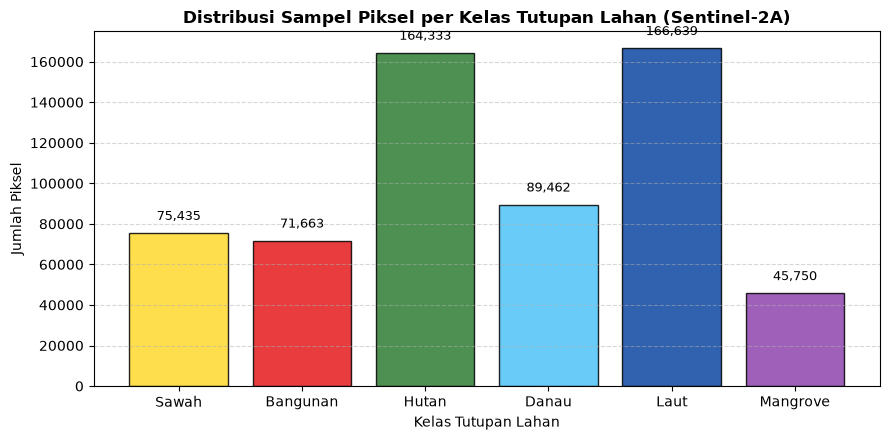

Grafik tersimpan di: D:\tugas psd\website-jupyterbook\UTS\output\02_distribusi_piksel.png


In [3]:
# Distribusi piksel per kelas
dist_piksel = df_raw.groupby(['label', 'label_teks']).size().reset_index(name='jumlah_piksel')
dist_piksel['persentase'] = (dist_piksel['jumlah_piksel'] / len(df_raw)) * 100
dist_piksel = dist_piksel.sort_values(by='label')

csv_dist = OUT_DIR / "02_distribusi_kelas_piksel.csv"
dist_piksel.to_csv(csv_dist, index=False)
print("=== DISTRIBUSI PIKSEL PER KELAS ===")
display(dist_piksel)

# Visualisasi Bar Plot Distribusi Piksel
PALET_KELAS = {
    'Sawah': '#FFD92F',
    'Bangunan': '#E41A1C',
    'Hutan': '#2E7D32',
    'Danau': '#4FC3F7',
    'Laut': '#0D47A1',
    'Mangrove': '#8E44AD'
}

plt.figure(figsize=(9, 4.5))
warna_bars = [PALET_KELAS.get(row['label_teks'], '#333333') for _, row in dist_piksel.iterrows()]
bars = plt.bar(dist_piksel['label_teks'], dist_piksel['jumlah_piksel'], color=warna_bars, edgecolor='black', alpha=0.85)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 5000, f"{int(yval):,}", ha='center', va='bottom', fontsize=9)

plt.title('Distribusi Sampel Piksel per Kelas Tutupan Lahan (Sentinel-2A)', fontsize=12, fontweight='bold')
plt.xlabel('Kelas Tutupan Lahan', fontsize=10)
plt.ylabel('Jumlah Piksel', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

png_dist = OUT_DIR / "02_distribusi_piksel.png"
plt.savefig(png_dist, dpi=200)
plt.show()
print(f"Grafik tersimpan di: {png_dist}")

### 3. Profil Karakteristik Spektral (*Spectral Signatures*)
Kurva pantulan spektral rata-rata pada 5 band (B02, B03, B04, B08, B11) dan 4 indeks spektral (NDVI, NDWI, MNDWI, NDBI):
- Vegetasi (Hutan, Sawah, Mangrove): Memantulkan tinggi NIR (B08) dan menghasilkan NDVI tinggi.
- Badan Air (Danau, Laut): Memantulkan cahaya tampak biru/hijau dan menyerap kuat NIR/SWIR, menghasilkan NDWI/MNDWI positif tinggi.
- Lahan Bangunan: Pantulan relatif seragam di saluran tampak dan tinggi di SWIR (B11), menghasilkan NDBI positif.

=== RATA-RATA NILAI BAND SPEKTRAL ===


,B02,B03,B04,B08,B11
label_teks,,,,,
Bangunan,852.45,1043.27,1144.16,2430.63,2667.68
Danau,713.07,924.55,709.14,828.63,778.45
Hutan,521.09,731.60,689.59,2802.75,2251.79
Laut,748.76,792.18,587.50,409.02,374.01
Mangrove,289.46,541.68,373.36,2651.75,1136.57
Sawah,648.27,878.61,844.71,2774.38,2065.06


=== RATA-RATA INDEKS SPEKTRAL ===


,NDVI,NDWI,MNDWI,NDBI
label_teks,,,,
Bangunan,0.3596,-0.3973,-0.4435,0.0503
Danau,-0.1426,0.2683,0.2533,0.0305
Hutan,0.5920,-0.5698,-0.5119,-0.1044
Laut,-0.1551,0.2972,0.3522,-0.0771
Mangrove,0.7435,-0.6500,-0.3452,-0.4046
Sawah,0.5236,-0.5016,-0.3897,-0.1511


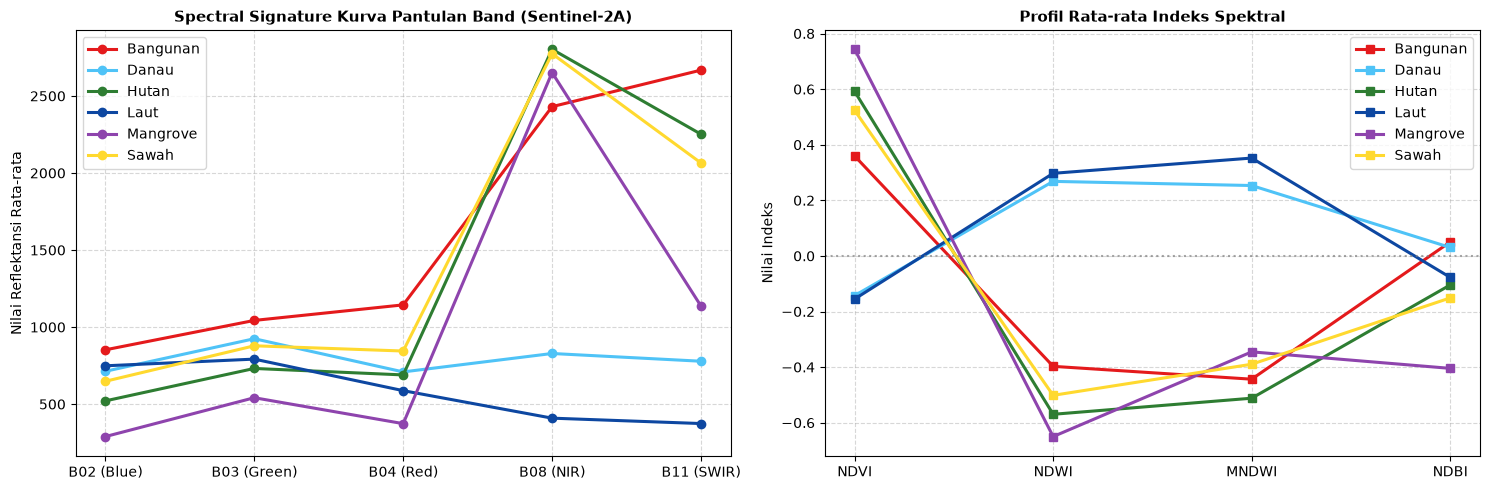

Grafik spektral tersimpan di: D:\tugas psd\website-jupyterbook\UTS\output\02_spectral_signatures.png


In [4]:
# Profil Rata-Rata Spektral per Kelas
mean_bands = df_raw.groupby('label_teks')[['B02', 'B03', 'B04', 'B08', 'B11']].mean()
print("=== RATA-RATA NILAI BAND SPEKTRAL ===")
display(mean_bands.round(2))

mean_indices = df_raw.groupby('label_teks')[['NDVI', 'NDWI', 'MNDWI', 'NDBI']].mean()
print("=== RATA-RATA INDEKS SPEKTRAL ===")
display(mean_indices.round(4))

# Visualisasi Spectral Signatures
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot Band Spektral
bands_names = ['B02 (Blue)', 'B03 (Green)', 'B04 (Red)', 'B08 (NIR)', 'B11 (SWIR)']
for label_name, row in mean_bands.iterrows():
    ax1.plot(bands_names, row.values, marker='o', linewidth=2.2, label=label_name, color=PALET_KELAS.get(label_name, '#333333'))
ax1.set_title('Spectral Signature Kurva Pantulan Band (Sentinel-2A)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Nilai Reflektansi Rata-rata', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left')

# Plot Indeks Spektral
indices_names = ['NDVI', 'NDWI', 'MNDWI', 'NDBI']
for label_name, row in mean_indices.iterrows():
    ax2.plot(indices_names, row.values, marker='s', linewidth=2.2, label=label_name, color=PALET_KELAS.get(label_name, '#333333'))
ax2.axhline(0, color='gray', linestyle=':', alpha=0.7)
ax2.set_title('Profil Rata-rata Indeks Spektral', fontsize=11, fontweight='bold')
ax2.set_ylabel('Nilai Indeks', fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right')

plt.tight_layout()
png_spec = OUT_DIR / "02_spectral_signatures.png"
plt.savefig(png_spec, dpi=200)
plt.show()
print(f"Grafik spektral tersimpan di: {png_spec}")

### 4. Matriks Korelasi Pearson Fitur Spektral
Menganalisis korelasi linier antar fitur 5 band dan 4 indeks spektral.

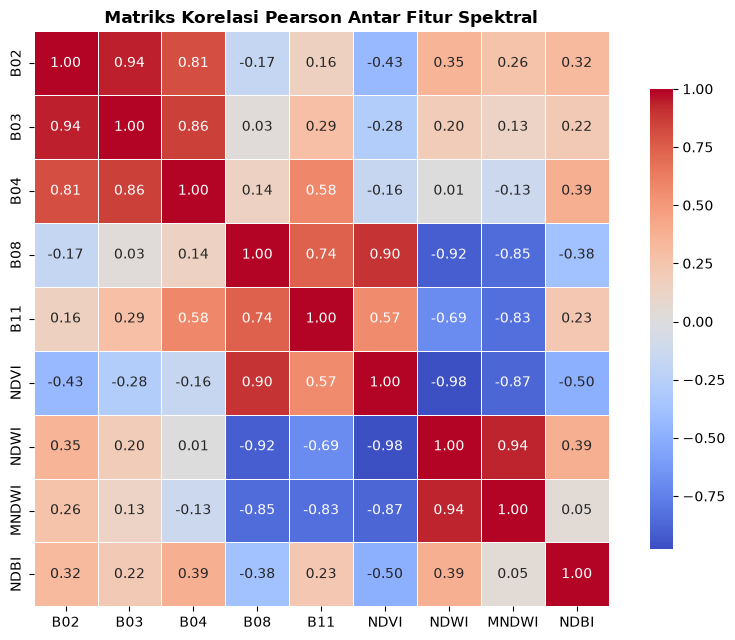

Matriks korelasi tersimpan di: D:\tugas psd\website-jupyterbook\UTS\output\02_matriks_korelasi.png


In [5]:
corr_matrix = df_raw[FITUR_SPEKTRAL].corr()

plt.figure(figsize=(8.5, 6.5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Matriks Korelasi Pearson Antar Fitur Spektral', fontsize=12, fontweight='bold')
plt.tight_layout()

png_corr = OUT_DIR / "02_matriks_korelasi.png"
plt.savefig(png_corr, dpi=200)
plt.show()
print(f"Matriks korelasi tersimpan di: {png_corr}")

In [6]:
# Mencetak daftar seluruh berkas keluaran dari Notebook 02
print("=== DAFTAR BERKAS KELUARAN NOTEBOOK 02 ===")
for f in [csv_dist, png_dist, png_spec, png_corr]:
    print(f"- {f.name} ({f.stat().st_size:,} bytes)")

=== DAFTAR BERKAS KELUARAN NOTEBOOK 02 ===
- 02_distribusi_kelas_piksel.csv (251 bytes)
- 02_distribusi_piksel.png (75,883 bytes)
- 02_spectral_signatures.png (317,777 bytes)
- 02_matriks_korelasi.png (184,887 bytes)


### 5. Pemeriksaan Spasial terhadap Batas Administrasi Jawa Timur
Memeriksa apakah centroid tiap poligon sampel berada di dalam batas administrasi resmi Jawa Timur (`data/jawatimur.geojson`). Ini menggantikan pendekatan bounding box persegi sebelumnya yang memasukkan koordinat Pulau Bali.

**Kebijakan terhadap sampel di luar batas:**
- Sampel kelas **air (Laut, Danau, Mangrove)** di luar batas daratan adalah **wajar** (geojson = batas daratan). Tidak dihapus, ditandai `dalam_jatim=False`.
- Sampel kelas **daratan (Sawah, Bangunan, Hutan)** di luar batas dicatat sebagai potensi anomali. Parameter `HAPUS_DARATAN_LUAR_BATAS` mengontrol apakah akan dihapus (default: `False`).


In [ ]:
import sys
# Pastikan modul wilayah dapat diimpor
sys.path.insert(0, str(BASE_DIR))
from wilayah import muat_batas, titik_di_dalam

# ── Parameter ──────────────────────────────────────────────────────────────
# Jika True, hapus sampel kelas daratan di luar batas dari pelatihan.
# Default False: semua sampel tetap dipakai, kompatibel dengan versi sebelumnya.
HAPUS_DARATAN_LUAR_BATAS = False
# ───────────────────────────────────────────────────────────────────────────

print("Memuat batas administrasi Jawa Timur...")
gdf_batas = muat_batas(DATA_DIR / "jawatimur.geojson")
bbox_aktual = {
    'west':  float(gdf_batas.total_bounds[0]),
    'south': float(gdf_batas.total_bounds[1]),
    'east':  float(gdf_batas.total_bounds[2]),
    'north': float(gdf_batas.total_bounds[3]),
}
print(f"Bounds aktual dari geojson: {bbox_aktual}")
print(f"(Sebelumnya: west=110.89, south=-8.84, east=115.45, north=-6.65 -- memasukkan Bali)")

# Hitung centroid per poligon
df_centroid = df_agg.copy()  # df_agg berisi rata-rata fitur per poligon
if 'lon' in df_centroid.columns and 'lat' in df_centroid.columns:
    pass
else:
    # Hitung dari df_piksel jika df_agg tidak punya lon/lat
    df_centroid = df_piksel.groupby('poligon_id').agg(
        label_teks=('label_teks', 'first'),
        label=('label', 'first'),
        lon=('lon', 'mean'),
        lat=('lat', 'mean'),
        n_piksel=('sampel_id', 'count'),
    ).reset_index()

print(f"\nMenguji {len(df_centroid)} centroid poligon terhadap batas Jawa Timur...")
dalam_series = titik_di_dalam(df_centroid, gdf_batas, lon='lon', lat='lat')
df_centroid['dalam_jatim'] = dalam_series.values

# Tabel ringkasan per kelas
df_report = df_centroid.groupby(['label_teks', 'dalam_jatim']).agg(
    n_poligon=('poligon_id', 'count'),
    n_piksel=('n_piksel', 'sum') if 'n_piksel' in df_centroid.columns else ('poligon_id', 'count'),
).reset_index()
df_report['dalam_jatim'] = df_report['dalam_jatim'].map({True: 'Di Dalam', False: 'Di Luar'})
print("\n=== Tabel Sampel vs Batas Jawa Timur ===")
display(df_report)

# Simpan
df_report.to_csv(OUT_DIR / "02_sampel_vs_batas.csv", index=False)
print(f"Disimpan ke output/02_sampel_vs_batas.csv")

# Identifikasi sampel daratan di luar batas
df_daratan_luar = df_centroid[
    (~df_centroid['dalam_jatim']) &
    (~df_centroid['label_teks'].isin(['Laut', 'Danau', 'Mangrove']))
]
df_air_luar = df_centroid[
    (~df_centroid['dalam_jatim']) &
    (df_centroid['label_teks'].isin(['Laut', 'Danau', 'Mangrove']))
]

if len(df_daratan_luar) > 0:
    print(f"\n[LAPORAN] {len(df_daratan_luar)} poligon DARATAN di luar batas (potensi anomali):")
    display(df_daratan_luar[['poligon_id', 'label_teks', 'lon', 'lat']])
    if HAPUS_DARATAN_LUAR_BATAS:
        id_hapus = set(df_daratan_luar['poligon_id'])
        sebelum = len(df_centroid)
        df_centroid = df_centroid[~df_centroid['poligon_id'].isin(id_hapus)].copy()
        print(f"[HAPUS] HAPUS_DARATAN_LUAR_BATAS=True: {sebelum - len(df_centroid)} poligon dihapus.")
    else:
        print(f"[INFO] HAPUS_DARATAN_LUAR_BATAS=False (default): semua sampel tetap dipakai.")
        print("[INFO] Metrik model TIDAK berubah dari versi sebelumnya.")
else:
    print("\n[OK] Tidak ada poligon kelas daratan di luar batas.")

if len(df_air_luar) > 0:
    print(f"\n[INFO] {len(df_air_luar)} poligon AIR/PESISIR di luar batas -- WAJAR, tidak dihapus.")

# Peta statis sampel dalam vs luar batas
import matplotlib.pyplot as plt
import geopandas as gpd

fig, ax = plt.subplots(1, 1, figsize=(12, 7))
gdf_batas.plot(ax=ax, color='none', edgecolor='#2c3e50', linewidth=1.5, label='Batas Jawa Timur')
df_dalam = df_centroid[df_centroid['dalam_jatim'] == True]
df_luar  = df_centroid[df_centroid['dalam_jatim'] == False]
ax.scatter(df_dalam['lon'], df_dalam['lat'],
           c='green', s=15, alpha=0.7, label=f'Di Dalam ({len(df_dalam)} poligon)', zorder=3)
if len(df_luar) > 0:
    ax.scatter(df_luar['lon'], df_luar['lat'],
               c='red', s=30, alpha=0.9, marker='x', label=f'Di Luar ({len(df_luar)} poligon)', zorder=4)
ax.set_title('Centroid Poligon Sampel vs Batas Administrasi Jawa Timur', fontsize=13, fontweight='bold')
ax.set_xlabel('Bujur (derajat BT)'); ax.set_ylabel('Lintang (derajat LS)')
ax.legend(loc='upper left', fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "02_sampel_vs_batas_peta.png", dpi=120, bbox_inches='tight')
plt.show()
print("Peta sampel vs batas disimpan ke output/02_sampel_vs_batas_peta.png")
